# CODE 5.1: Set the Alarm Rules

> **Goal:** turn the scores of both models into alarms, and lock the alarm limit of each model on March, before any test window gets a score.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/time_split.csv` (1.2), `results/signals_used.json` (4.1), `models/isolation_forest.joblib` (4.1) and `models/lstm_autoencoder.pt` (4.2).
> - **Output:** `results/alarm_rules.json`: the alarm rule and the locked limits of both models. At the end you should see **ALL CHECKS PASSED**.
>
> The test windows (April to August) are dropped right after loading, and the grid is cut at the end of March. Nothing in this notebook can see the test months.

### From a Score to an Alarm

> Every window gets a number from each model: a **score** from Isolation Forest (notebook 4.1) and an **error** from the LSTM (notebook 4.2). In both, higher means more unusual. A **limit** turns this number into a yes or no: a window above the limit looks unusual.
>
> One window above the limit is not enough for an alarm: it can be a short blip. So the rule has three parts (the picture shows them with made-up numbers):
>
> 1. **3 in a row.** An alarm goes off at the end of the third window in a row above the limit. The windows are 5 minutes apart, so the first alarm comes at least 10 minutes after the first window above the limit.
> 2. **The alarm stays on** while the windows stay above the limit: every further window above it is an alarm too.
> 3. **Nearby alarms are one event.** One problem keeps the windows above the limit for a while and gives many alarms, but a maintenance team would see them as one warning. So alarms at most 60 minutes apart belong to one **event**. A new event needs more than 60 minutes without an alarm: then its window (the last 60 minutes) does not share a single minute with the window of the previous alarm.
>
> False alarms are counted as events, not as single alarms.

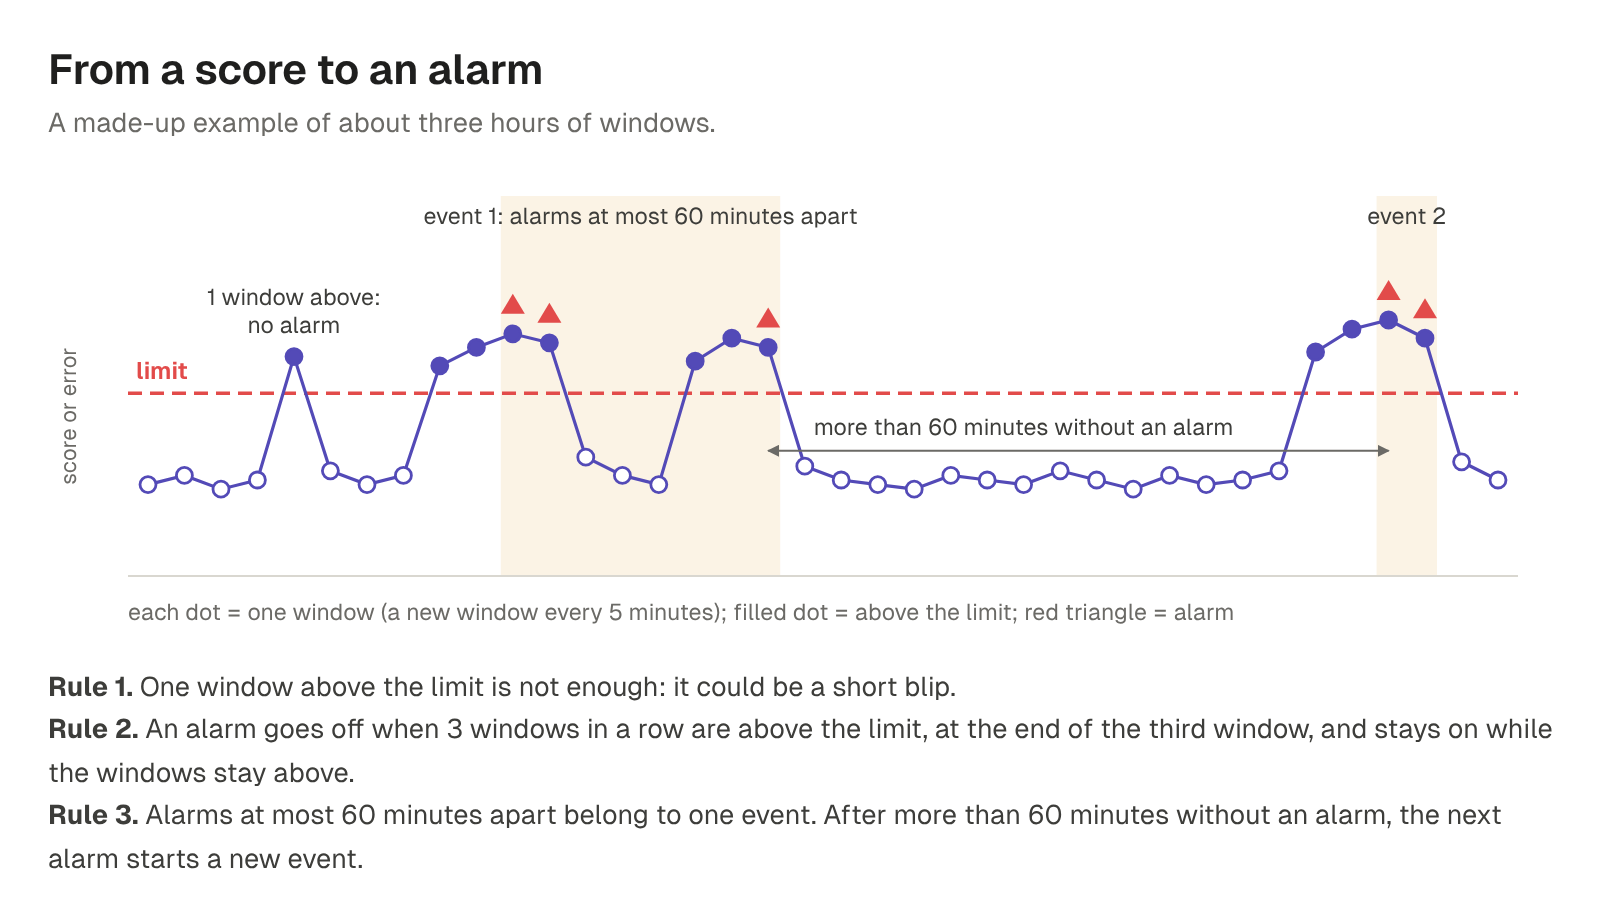

### Where the Limit Comes From

> A low limit warns early, but it also cries wolf more often. A high limit gives fewer false alarms, but it may notice a leak late, or not at all. We settle this trade-off with one rule:
>
> **The limit of a model is the lowest limit that gives at most 1 false alarm event per week in March.**
>
> - **Why March?** March is the validation month: no leak is reported in it, so every alarm in March is a false alarm, and the models never learned from it. The test months are not used.
> - **Why 1 per week?** A team can look into one false alarm a week. With many more, they start to ignore the alarms, also the real ones.
> - **Why the lowest such limit?** Warning early is the goal of this project, so we take the most sensitive limit that the budget allows.
> - **Why one limit per model?** Their numbers are on different scales: the score of the forest has a ceiling, the error of the LSTM has none (notebooks 4.1 and 4.2).
> - **A week of what?** Of **monitored time**: the number of windows times 5 minutes, because a new window starts every 5 minutes. Hours without a window (the train switched off, or data missing) are watched by no model, so they do not count.

### Decision: Unusual March Hours Do Not Count Here

> After notebook 3.2 we decided: March holds hours that are clearly not normal, although no failure is reported in March. If these hours counted as false alarms, they would decide the limit, not the normal March days. So they are **left out of the counting** when the limit is set: their alarms are not counted, and their time is not monitored time. The alarm rule itself runs the same way over every window.
>
> The rule that marks them is fixed here, with February and March only. A tick of the 10-second grid is marked when:
>
> - **the pump runs without a break for 30 minutes or more:** `DV_eletric` (the compressor pumps under load) stays 1 for at least 30 minutes in a row; or
> - **`LPS` is on:** the low-pressure switch says the air pressure fell below 7 bar (notebook 1.1).
>
> A window is marked when at least one of its 360 ticks is marked. A check makes sure that the rule marks nothing in February.
>
> - **The test months are judged without this:** from April to August, every window counts.
> - **What-if:** we also set a second limit with every March window counted. It is saved too, and used only in notebook 5.4, to show what this decision changes.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `hashlib`: folders and file paths, the rules file, and fingerprints of files (see "Fingerprints" below).
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts.
> - `joblib`: loads the Isolation Forest of notebook 4.1.
> - `torch` (PyTorch): rebuilds the LSTM autoencoder of notebook 4.2 and lets it redraw the windows.
> - `tqdm`: shows a progress bar while many limits are tried.

In [1]:
import os
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from tqdm import tqdm

### Variables

#### Folder Paths

> The inputs from notebooks 1.2, 3.1, 4.1 and 4.2, and the file this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
RULES_FILE = os.path.join(RESULTS_DIR, "alarm_rules.json")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
FOREST_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
LSTM_FILE = os.path.join(MODELS_DIR, "lstm_autoencoder.pt")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `SIGNALS`, `OIL_COLUMN`, `WINDOW_STEPS`, `EVAL_BATCH`: as in notebook 4.2, to cut the windows for the LSTM and measure their errors. `TICK_SECONDS`: one tick of the grid is 10 seconds.
> - `PUMP_COLUMN`, `LOW_PRESSURE_COLUMN`, `LONG_PUMP_MINUTES`: the rule for unusual March hours: the pump runs without a break for at least 30 minutes, or the low-pressure switch is on.
> - `TANK_COLUMN`, `STOP_MINUTES`, `LOW_PRESSURE_BAR`: for "A Clue: The Tanks After a Stop": the tank pressure, a stop of the train (no reading for at least 30 minutes), and the 7 bar below which `LPS` switches on.
> - `IN_A_ROW`, `WINDOW_STEP_MINUTES`: an alarm needs 3 windows in a row above the limit, each one 5 minutes after the one before.
> - `MERGE_GAP_MINUTES`: alarms at most 60 minutes apart belong to one event.
> - `MAX_FALSE_ALARMS_PER_WEEK`, `MINUTES_PER_WEEK`: the budget, at most 1 false alarm event per week of monitored time.
> - `MODEL_NAMES`, `VERSION_NAMES`: names for tables and charts. The main version leaves the unusual March hours out; the what-if version counts every window.
> - `HALF_OF_MARCH`: splits March into two halves, as in notebooks 3.2 to 4.2.
> - `CURVE_POINTS`: how many limits we try for the chart "False Alarms in March for Every Limit".

In [3]:
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
OIL_COLUMN = "Oil_temperature"
WINDOW_STEPS = 360
TICK_SECONDS = 10
EVAL_BATCH = 512

PUMP_COLUMN = "DV_eletric"
LOW_PRESSURE_COLUMN = "LPS"
LONG_PUMP_MINUTES = 30
TANK_COLUMN = "Reservoirs"
STOP_MINUTES = 30
LOW_PRESSURE_BAR = 7

IN_A_ROW = 3
WINDOW_STEP_MINUTES = 5
MERGE_GAP_MINUTES = 60
MAX_FALSE_ALARMS_PER_WEEK = 1
MINUTES_PER_WEEK = 7 * 24 * 60

MODEL_NAMES = {"isolation_forest": "Isolation Forest", "lstm_autoencoder": "LSTM autoencoder"}
VERSION_NAMES = {"main": "unusual hours left out (main)", "all_counted": "every window counted (what-if)"}
HALF_OF_MARCH = "2020-03-16 00:00:00"
CURVE_POINTS = 300

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Cut Many Windows at Once (from 4.2)

> `cut_windows()` is copied unchanged from notebook 4.2: it cuts the 360 ticks of every window out of the grid at once, and turns the oil temperature into a change since the first tick of the window.

In [5]:
def cut_windows(grid_values, end_indices, window_steps, oil_index):
    ticks = end_indices[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    windows = grid_values[ticks]
    windows[:, :, oil_index] -= windows[:, :1, oil_index]
    return windows

### The LSTM Autoencoder (from 4.2)

> `LSTMAutoencoder` is copied unchanged from notebook 4.2, so the saved weights fit into it: the encoder writes the note, the decoder redraws the window from it.

In [6]:
class LSTMAutoencoder(torch.nn.Module):
    def __init__(self, n_signals, memory_size):
        super().__init__()
        self.encoder = torch.nn.LSTM(input_size=n_signals, hidden_size=memory_size, batch_first=True)
        self.decoder = torch.nn.LSTM(input_size=memory_size, hidden_size=memory_size, batch_first=True)
        self.output = torch.nn.Linear(in_features=memory_size, out_features=n_signals)

    def forward(self, windows):
        _, (memory, _) = self.encoder(windows)
        note = memory[-1].unsqueeze(1).repeat(1, windows.shape[1], 1)
        redrawn, _ = self.decoder(note)
        return self.output(redrawn)

### Measure the Errors (from 4.2)

> `window_errors()` is copied unchanged from notebook 4.2: the error of every window, and its error for every signal. Here we only use the first one.

In [7]:
def window_errors(model, windows, batch_size):
    model.eval()
    parts = []
    with torch.no_grad():
        for start in range(0, len(windows), batch_size):
            batch = windows[start:start + batch_size]
            parts.append((model(batch) - batch).abs().mean(dim=1).cpu())
    per_signal = torch.cat(parts).numpy()
    return per_signal.mean(axis=1), per_signal

### Score Windows with the Forest (from 4.1)

> `anomaly_score()` is copied unchanged from notebook 4.1: scikit-learn's `score_samples()` with the sign flipped, so that a higher score means more unusual.

In [8]:
def anomaly_score(model, features):
    return -model.score_samples(features)

### Fingerprints

> A **fingerprint** (SHA-256) is a code of 64 characters computed from every byte of a file or a text. Change one byte and the code changes completely, like a seal on an envelope.
>
> `file_fingerprint()` computes the fingerprint of a file. We store the fingerprints of the two model files with the limits, so notebook 5.2 can check that it uses exactly the models these limits were set for.

In [9]:
def file_fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

> `rules_fingerprint()` computes the fingerprint of the rules themselves (everything in the rules file except the fingerprint). Notebook 5.2 computes it again: if anyone changed a limit by hand after this notebook, the two codes no longer match.

In [10]:
def rules_fingerprint(rules):
    text = json.dumps({key: value for key, value in rules.items() if key != "fingerprint"}, sort_keys=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

### Find Runs

> `find_runs()` finds every **run** of an on/off signal: a stretch of ticks in a row where it is on. It returns the first tick of every run and its length in ticks. An empty tick (no reading in the last 30 seconds, notebook 3.1) ends a run, because we cannot see that the run went on.

In [11]:
def find_runs(is_on):
    edges = np.diff(np.concatenate([[0], is_on.astype(int), [0]]))
    starts = np.flatnonzero(edges == 1)
    return starts, np.flatnonzero(edges == -1) - starts

### Mark Windows

> `marked_windows()` marks every window that holds at least one marked tick among its 360 ticks. It keeps a running count of the marked ticks along the grid: the count at the last tick of a window, minus the count just before its first tick, is the number of marked ticks inside the window.

In [12]:
def marked_windows(marked_ticks, end_indices, window_steps):
    running_count = np.concatenate([[0], np.cumsum(marked_ticks)])
    return running_count[end_indices + 1] - running_count[end_indices + 1 - window_steps] > 0

### Alarms: 3 Windows in a Row

> `alarm_windows()` applies the alarm rule to the windows of one model, in time order:
>
> 1. Find every window above the limit.
> 2. Count how many windows in a row are above it. The count starts again at every window below the limit, and after every gap: a window that does not come exactly 5 minutes after the one before (the train was switched off, or data is missing).
> 3. Every window with a count of at least `IN_A_ROW` is an alarm.
>
> It returns yes or no (True or False) for every window.

In [13]:
def alarm_windows(scores, ends, limit, in_a_row, step_minutes):
    above = pd.Series(scores > limit)
    restart = ~above | pd.Series(ends.diff().to_numpy() != np.timedelta64(step_minutes, "m"))
    run = above.astype(int).groupby(restart.cumsum()).cumsum()
    return (run >= in_a_row).to_numpy()

### Events: Nearby Alarms Count Once

> `find_events()` takes the alarms of the windows that count (`counted`), in time order, and groups them into events: an alarm more than `MERGE_GAP_MINUTES` after the alarm before it starts a new event. It returns one row per event: its first alarm, its last alarm, and how many alarms it holds.

In [14]:
def find_events(alarms, counted, ends, merge_gap_minutes):
    times = ends[alarms & counted].reset_index(drop=True)
    new_event = times.diff().isna() | (times.diff() > pd.Timedelta(minutes=merge_gap_minutes))
    events = times.groupby(new_event.cumsum()).agg(["min", "max", "size"])
    return events.rename(columns={"min": "first_alarm", "max": "last_alarm", "size": "alarms"}).reset_index(drop=True)

### Search the Limit

> `search_limit()` tries every March score of a model as the limit, from the highest to the lowest. A window is above the limit when its score is higher than the limit. For every limit, it counts the false alarm events. It stops at the first limit that gives more events than `max_events`, and returns the limit just before it: the lowest limit where this limit and every higher one keep the budget. It also returns the limit that broke the budget, for a check.
>
> Why stop at the first break, instead of taking the lowest limit anywhere that keeps the budget? Because the number of events does not always grow when the limit goes down: two nearby events can join into one. Far down, a limit could keep the budget by luck, with many higher limits around it breaking it.

In [15]:
def search_limit(scores, ends, counted, max_events, in_a_row, step_minutes, merge_gap_minutes):
    chosen = None
    for limit in np.unique(scores)[::-1]:
        alarms = alarm_windows(scores=scores, ends=ends, limit=limit, in_a_row=in_a_row, step_minutes=step_minutes)
        if len(find_events(alarms=alarms, counted=counted, ends=ends, merge_gap_minutes=merge_gap_minutes)) > max_events:
            return chosen, limit
        chosen = limit
    return chosen, None

## Load the Data

### Read the Files and Drop the Test Months

> We read the grid, the windows, the time split and the signal list. Only the February and March windows are kept, and the grid is cut before the first tick of April: everything after that is gone before anything else happens.

In [16]:
with np.load(GRID_FILE) as saved:
    grid_values, grid_signals, tick_seconds = saved["values"], saved["signals"].tolist(), saved["tick_seconds"]
    has_reading, scaled_columns = saved["has_reading"], saved["scaled_columns"].tolist()
    scale_mean, scale_std = saved["scale_mean"], saved["scale_std"]
df_windows = pd.read_parquet(WINDOWS_FILE)
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
validation_from = pd.Timestamp(split_table.loc["validation", "from"])
test_from = pd.Timestamp(split_table.loc["validation", "until (not included)"])
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_info = json.load(f)

windows_in_file, ticks_in_file = len(df_windows), len(grid_values)
df_windows = df_windows[df_windows["split"].isin(["train", "validation"])].reset_index(drop=True)
before_test = tick_seconds < test_from.value // 10**9
grid_values, has_reading, tick_times = grid_values[before_test], has_reading[before_test], pd.to_datetime(tick_seconds[before_test], unit="s")
is_train, is_march = (df_windows["split"] == "train").to_numpy(), (df_windows["split"] == "validation").to_numpy()

print(f"Windows in the file: {windows_in_file:,} | kept: {len(df_windows):,} (February {is_train.sum():,}, March {is_march.sum():,})")
print(f"Ticks in the grid: {ticks_in_file:,} | kept: {len(grid_values):,}, from {tick_times[0]} to {tick_times[-1]}")
check("only February and March are kept: the windows, and the grid ticks before April",
      set(df_windows["split"]) <= {"train", "validation"} and tick_times[-1] < test_from and df_windows["end_index"].max() < len(grid_values))

Windows in the file: 47,491 | kept: 13,984 (February 6,790, March 7,194)
Ticks in the grid: 1,841,760 | kept: 518,400, from 2020-02-01 00:00:00 to 2020-03-31 23:59:50
PASS  only February and March are kept: the windows, and the grid ticks before April


### Load the Two Models

> Both models come from the files of notebooks 4.1 and 4.2; they are not trained again. The forest is a joblib file: only load joblib files you made yourself, because loading one can run code (notebook 4.1). The LSTM file is loaded with `weights_only=True`, which cannot run code (notebook 4.2).

In [17]:
forest = joblib.load(FOREST_FILE)
FEATURE_COLUMNS = signals_info["isolation_forest_features"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
saved_lstm = torch.load(LSTM_FILE, map_location=device, weights_only=True)
lstm = LSTMAutoencoder(n_signals=len(saved_lstm["signals"]), memory_size=saved_lstm["memory_size"]).to(device)
lstm.load_state_dict(saved_lstm["state_dict"])

print(f"Isolation Forest: {len(forest.estimators_)} trees, {forest.n_features_in_} summary numbers")
print(f"LSTM autoencoder: weights of round {saved_lstm['best_epoch']}, {len(saved_lstm['signals'])} signals, a note of {saved_lstm['memory_size']} numbers | device: {device.type}")
check("the forest uses the summary numbers saved by notebook 4.1", list(forest.feature_names_in_) == FEATURE_COLUMNS)
check("the LSTM uses the signals saved by notebook 4.1, and windows of 360 ticks",
      saved_lstm["signals"] == signals_info["signals"] and saved_lstm["window_steps"] == WINDOW_STEPS)

Isolation Forest: 300 trees, 40 summary numbers
LSTM autoencoder: weights of round 149, 12 signals, a note of 64 numbers | device: cuda
PASS  the forest uses the summary numbers saved by notebook 4.1
PASS  the LSTM uses the signals saved by notebook 4.1, and windows of 360 ticks


## Score February and March

### The Score and the Error of Every Window

> Every February and March window gets its score from the forest and its error from the LSTM, exactly as in notebooks 4.1 and 4.2. The LSTM errors are computed month by month, in the same groups of windows as in notebook 4.2, so that they come out the same as there, also on a GPU. The table repeats the middle (median) and the highest values, to compare with the limits later.

In [18]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
df_windows["isolation_forest"] = anomaly_score(model=forest, features=df_windows[FEATURE_COLUMNS])
signal_columns = [grid_signals.index(signal) for signal in signals_info["signals"]]
windows = cut_windows(grid_values=grid_values, end_indices=df_windows["end_index"].to_numpy(), window_steps=WINDOW_STEPS,
                      oil_index=grid_signals.index(OIL_COLUMN))
inputs = np.ascontiguousarray(windows[:, :, signal_columns])
del windows
df_windows["lstm_autoencoder"] = np.nan
for mask in [is_train, is_march]:
    df_windows.loc[mask, "lstm_autoencoder"] = window_errors(model=lstm, windows=torch.from_numpy(inputs[mask]).to(device), batch_size=EVAL_BATCH)[0]
del inputs

summary = pd.DataFrame({f"{month} {statistic}": [df_windows.loc[mask, model].agg(statistic) for model in MODEL_NAMES]
                        for month, mask in [("February", is_train), ("March", is_march)] for statistic in ["median", "max"]},
                       index=list(MODEL_NAMES.values()))
display(summary.round(3))
check("every February and March window has a finite score and error", np.isfinite(df_windows[list(MODEL_NAMES)].to_numpy()).all())

,February median,February max,March median,March max
Isolation Forest,0.425,0.735,0.61,0.756
LSTM autoencoder,0.074,0.458,0.25,2.738


PASS  every February and March window has a finite score and error


> **What we see:** the same values as in notebooks 4.1 and 4.2, because the models did not change. Keep two things in mind for the limits: the highest March score of the forest is only a little above its highest February score (the ceiling of notebook 4.1), while the highest March error of the LSTM is several times its highest February error.

## Mark the Unusual March Hours

### Long Pump Runs and the Low-Pressure Switch

> We find every run of the pump (`DV_eletric` = 1) on the grid, in February and March, and every moment with `LPS` on. The table lists the pump runs of at least `LONG_PUMP_MINUTES` minutes.

In [19]:
pump_on = grid_values[:, grid_signals.index(PUMP_COLUMN)] == 1
low_pressure = grid_values[:, grid_signals.index(LOW_PRESSURE_COLUMN)] == 1
run_starts, run_lengths = find_runs(is_on=pump_on)
low_starts, low_lengths = find_runs(is_on=low_pressure)
run_in_february, low_in_february = tick_times[run_starts] < validation_from, tick_times[low_starts] < validation_from
is_long = run_lengths >= LONG_PUMP_MINUTES * 60 // TICK_SECONDS
in_long_run = np.zeros(len(pump_on), dtype=bool)
for start, length in zip(run_starts[is_long], run_lengths[is_long]):
    in_long_run[start:start + length] = True

february_longest = run_lengths[run_in_february].max() * TICK_SECONDS / 60
longer_than_february = (~run_in_february & (run_lengths * TICK_SECONDS / 60 > february_longest) & ~is_long).sum()
long_table = pd.DataFrame({"pump on from": tick_times[run_starts[is_long]].strftime("%d %b %H:%M"),
                           "until": tick_times[run_starts[is_long] + run_lengths[is_long] - 1].strftime("%d %b %H:%M"),
                           "hours": (run_lengths[is_long] * TICK_SECONDS / 3600).round(2)})
display(long_table)
print(f"Pump runs: February {run_in_february.sum():,} (longest {february_longest:.1f} minutes) | March {(~run_in_february).sum():,}")
print(f"March runs of at least {LONG_PUMP_MINUTES} minutes: {is_long.sum()} (table above) | longer than every February run, "
      f"but shorter than {LONG_PUMP_MINUTES} minutes: {longer_than_february} (not marked)")
print(f"Moments with {LOW_PRESSURE_COLUMN} on: February {low_in_february.sum()} | March {(~low_in_february).sum()}, "
      f"from {low_lengths.min() * TICK_SECONDS / 60:.1f} to {low_lengths.max() * TICK_SECONDS / 60:.1f} minutes long")
check(f"the rule marks nothing in February: no pump run of {LONG_PUMP_MINUTES} minutes or more, and {LOW_PRESSURE_COLUMN} never on",
      not (is_long & run_in_february).any() and not low_in_february.any())

,pump on from,until,hours
0,06 Mar 21:42,06 Mar 23:00,1.29
1,11 Mar 05:15,11 Mar 06:10,0.92
2,12 Mar 00:16,12 Mar 11:49,11.56
3,26 Mar 04:00,26 Mar 04:53,0.88
4,27 Mar 07:12,27 Mar 11:38,4.44
5,28 Mar 07:22,28 Mar 08:50,1.46
6,28 Mar 23:05,29 Mar 19:49,20.74


Pump runs: February 1,165 (longest 4.2 minutes) | March 1,715
March runs of at least 30 minutes: 7 (table above) | longer than every February run, but shorter than 30 minutes: 67 (not marked)
Moments with LPS on: February 0 | March 18, from 0.7 to 22.8 minutes long
PASS  the rule marks nothing in February: no pump run of 30 minutes or more, and LPS never on


> **What we see:** in February, the pump never ran longer than a few minutes in one go, and the low-pressure switch never came on. So the rule marks nothing in February: it only finds hours that February never had. In March it finds the long pump runs in the table (the 5 stretches of notebook 3.2, plus two runs of just under an hour, on 11 and 26 March) and a number of short moments with `LPS` on.
>
> The table measures every run tick by tick, so its hours can be a little longer than the stretches of notebook 3.2, which were measured with whole windows.
>
> March also has pump runs that are longer than every February run, but shorter than 30 minutes (counted above). They are not marked, so their alarms count as false alarms. This makes the limits stricter, not looser: the rule only removes the clearest cases.

### A Clue: The Tanks After a Stop

> The rule finds **what** happened in March, not **why**. The data cannot say for sure: no failure and no maintenance is reported in March (notebook 1.2). But one more look gives a clue.
>
> When the train is switched off, the compressor stops and the readings stop too: these are the gaps of notebook 1.1. Tanks without a leak keep their air while the train stands still, like a bicycle tyre that is still hard the next morning. So for every **stop** (no reading for at least `STOP_MINUTES` minutes) we take the tank pressure (`Reservoirs`) at the first tick after it, in February and in March.
>
> This clue does not change the rule above. It only helps to understand the marked hours.

,stops,middle_stop_hours,lowest_tank_bar,middle_tank_bar,below 7 bar
month,,,,,
February,21,3.58,7.67,9.88,0
March,22,4.28,0.71,4.76,17


Moments with LPS on that begin at the first tick after a stop: 11 of 18


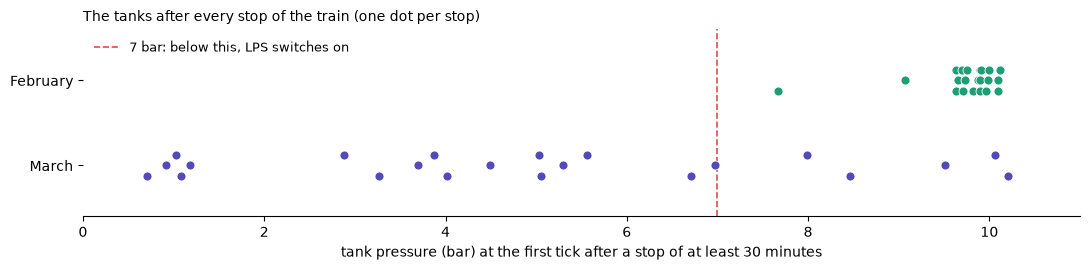

In [20]:
tank_index = scaled_columns.index(TANK_COLUMN)
tank_bar = grid_values[:, grid_signals.index(TANK_COLUMN)] * scale_std[tank_index] + scale_mean[tank_index]
stop_starts, stop_lengths = find_runs(is_on=~has_reading)
is_stop = (stop_lengths >= STOP_MINUTES * 60 // TICK_SECONDS) & (stop_starts + stop_lengths < len(tank_bar))
restart_ticks = stop_starts[is_stop] + stop_lengths[is_stop]
df_restarts = pd.DataFrame({"month": np.where(tick_times[restart_ticks] < validation_from, "February", "March"),
                            "stop_hours": stop_lengths[is_stop] * TICK_SECONDS / 3600, "tank_bar": tank_bar[restart_ticks]})
df_restarts["below_limit"] = df_restarts["tank_bar"] < LOW_PRESSURE_BAR
restart_table = df_restarts.groupby("month").agg(stops=("tank_bar", "size"), middle_stop_hours=("stop_hours", "median"),
                                                 lowest_tank_bar=("tank_bar", "min"), middle_tank_bar=("tank_bar", "median"),
                                                 below_limit=("below_limit", "sum"))
display(restart_table.round(2).rename(columns={"below_limit": f"below {LOW_PRESSURE_BAR} bar"}))
print(f"Moments with {LOW_PRESSURE_COLUMN} on that begin at the first tick after a stop: "
      f"{np.isin(low_starts[~low_in_february], restart_ticks).sum()} of {(~low_in_february).sum()}")

fig, ax = plt.subplots(figsize=(11, 2.8))
for row, (month, color) in enumerate([("March", "#534AB7"), ("February", "#1D9E75")]):
    pressures = np.sort(df_restarts.loc[df_restarts["month"] == month, "tank_bar"].to_numpy())
    ax.scatter(pressures, row + (np.arange(len(pressures)) % 3 - 1) * 0.12, s=42, color=color, edgecolor="white", linewidth=0.6, zorder=3)
ax.axvline(LOW_PRESSURE_BAR, color="#E24B4A", linestyle="--", linewidth=1.2, label=f"{LOW_PRESSURE_BAR} bar: below this, {LOW_PRESSURE_COLUMN} switches on")
ax.set_yticks([0, 1], labels=["March", "February"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0, 11)
ax.set_xlabel(f"tank pressure (bar) at the first tick after a stop of at least {STOP_MINUTES} minutes")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("The tanks after every stop of the train (one dot per stop)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

> **What we see:** in February the tanks kept their air: after every stop, the pressure was still above 7 bar. In March the tanks were often much emptier after a stop, sometimes almost empty, although the stops lasted about as long as in February (see the table). Many of the moments with `LPS` on are exactly these starts (printed above): the tanks fill up again, and on the way up they pass 7 bar.
>
> Air that disappears while the train stands still, and long pump runs in which the pressure does not rise, both look like air escaping somewhere, as with a leak. But no leak is reported in March, so this stays a clue, not a fact. That is why the marked hours count neither as healthy nor as a leak: they are left out. It also means that March may not be fully healthy outside the marked hours either. Notebook 5.4 comes back to this.

### Marked Windows

> A window is marked when at least one of its 360 ticks is marked. So a long pump run also marks the windows that only touch it: the windows whose hour holds the start or the end of the run. The table shows every stretch of marked windows in a row, and why it is marked.

In [21]:
end_indices = df_windows["end_index"].to_numpy()
df_windows["unusual"] = marked_windows(marked_ticks=in_long_run | low_pressure, end_indices=end_indices, window_steps=WINDOW_STEPS)
df_windows["long_pump_run"] = marked_windows(marked_ticks=in_long_run, end_indices=end_indices, window_steps=WINDOW_STEPS)
df_windows["LPS_on"] = marked_windows(marked_ticks=low_pressure, end_indices=end_indices, window_steps=WINDOW_STEPS)
marked = df_windows[df_windows["unusual"]]
new_stretch = marked["end"].diff() != pd.Timedelta(minutes=WINDOW_STEP_MINUTES)
stretch_table = marked.groupby(new_stretch.cumsum().to_numpy()).agg(first_window_end=("end", "min"), last_window_end=("end", "max"),
                                                                    windows=("end", "size"), long_pump_run=("long_pump_run", "any"),
                                                                    LPS_on=("LPS_on", "any"))
display(stretch_table.assign(first_window_end=stretch_table["first_window_end"].dt.strftime("%d %b %H:%M"),
                             last_window_end=stretch_table["last_window_end"].dt.strftime("%d %b %H:%M")))

marked_in_march = df_windows.loc[is_march, "unusual"]
never_rested = is_march & (df_windows["drop_bar_per_min"] == 0).to_numpy()
print(f"Marked windows: February {df_windows.loc[is_train, 'unusual'].sum()} | March {marked_in_march.sum():,} of {is_march.sum():,} "
      f"({marked_in_march.mean():.1%}), in {len(stretch_table)} stretches")
print(f"Marked because of a long pump run: {df_windows.loc[is_march, 'long_pump_run'].sum():,} | because of {LOW_PRESSURE_COLUMN}: "
      f"{df_windows.loc[is_march, 'LPS_on'].sum()} | both: {(df_windows.loc[is_march, 'long_pump_run'] & df_windows.loc[is_march, 'LPS_on']).sum()}")
check("every March window where the pump never rested (notebook 3.2) is marked", never_rested.any() and df_windows.loc[never_rested, "unusual"].all())

,first_window_end,last_window_end,windows,long_pump_run,LPS_on
1,06 Mar 21:45,06 Mar 23:55,27,True,False
2,11 Mar 05:20,11 Mar 07:10,23,True,False
3,11 Mar 23:40,11 Mar 23:45,2,False,True
4,12 Mar 00:20,12 Mar 13:10,155,True,True
5,14 Mar 07:30,14 Mar 07:30,1,False,True
6,15 Mar 09:30,15 Mar 09:30,1,False,True
7,16 Mar 05:35,16 Mar 05:35,1,False,True
8,26 Mar 04:05,26 Mar 05:50,22,True,False
9,27 Mar 07:15,27 Mar 12:35,65,True,False
10,28 Mar 07:25,28 Mar 08:50,18,True,False


Marked windows: February 0 | March 564 of 7,194 (7.8%), in 12 stretches
Marked because of a long pump run: 541 | because of LPS: 36 | both: 13
PASS  every March window where the pump never rested (notebook 3.2) is marked


> **What we see:** most marked windows belong to the long pump runs, and the two largest stretches are on 12 March and on 29 March, as in notebook 3.2. `LPS` adds a few short stretches, some only one window long: windows only exist where the whole hour has data (notebook 3.1), so a short moment does not always mark many windows. All the windows of notebook 3.2 where the pump never rested are marked (the check above).

### Monitored Time

> The monitored time of March is its number of windows times 5 minutes. In the main version, the marked windows are taken out. With the budget of 1 false alarm event per week, the monitored weeks decide how many false alarm events March may have.

In [22]:
counted = {"main": ~marked_in_march.to_numpy(), "all_counted": np.ones(is_march.sum(), dtype=bool)}
weeks = {version: mask.sum() * WINDOW_STEP_MINUTES / MINUTES_PER_WEEK for version, mask in counted.items()}
max_events = {version: MAX_FALSE_ALARMS_PER_WEEK * value for version, value in weeks.items()}

for version, mask in counted.items():
    print(f"{VERSION_NAMES[version]}: {mask.sum():,} windows x {WINDOW_STEP_MINUTES} minutes = {weeks[version]:.2f} weeks "
          f"-> at most {int(np.floor(max_events[version]))} false alarm events in March")

unusual hours left out (main): 6,630 windows x 5 minutes = 3.29 weeks -> at most 3 false alarm events in March
every window counted (what-if): 7,194 windows x 5 minutes = 3.57 weeks -> at most 3 false alarm events in March


> **What we see:** March has 31 days, but fewer monitored weeks: in many hours there is no complete window. Leaving out the marked windows removes a little more time. Both versions allow the same number of false alarm events (printed above); what differs is which windows can make one.

## Set the Limits

### Search from High to Low

> For each model and each version, `search_limit()` finds the lowest limit that keeps the budget in March. The table also shows how many February windows, from the month the models learned from, lie above each limit.

In [23]:
df_march = df_windows[is_march].reset_index(drop=True)
march_ends = df_march["end"]
limits, first_breaks, march_events = {}, {}, {}
for model in MODEL_NAMES:
    for version in VERSION_NAMES:
        scores = df_march[model].to_numpy()
        limits[model, version], first_breaks[model, version] = search_limit(scores=scores, ends=march_ends, counted=counted[version],
                                                                            max_events=max_events[version], in_a_row=IN_A_ROW,
                                                                            step_minutes=WINDOW_STEP_MINUTES, merge_gap_minutes=MERGE_GAP_MINUTES)
        alarms = alarm_windows(scores=scores, ends=march_ends, limit=limits[model, version], in_a_row=IN_A_ROW, step_minutes=WINDOW_STEP_MINUTES)
        march_events[model, version] = find_events(alarms=alarms, counted=counted[version], ends=march_ends, merge_gap_minutes=MERGE_GAP_MINUTES)

limit_table = pd.DataFrame([{"model": MODEL_NAMES[model], "version": VERSION_NAMES[version], "limit": f"{limits[model, version]:.4f}",
                             "false alarm events in March": len(march_events[model, version]),
                             "per week": f"{len(march_events[model, version]) / weeks[version]:.2f}",
                             "February windows above": f"{(df_windows.loc[is_train, model] > limits[model, version]).mean():.2%}"}
                            for model in MODEL_NAMES for version in VERSION_NAMES])
display(limit_table)

one_lower = {}
for (model, version), limit in first_breaks.items():
    alarms = alarm_windows(scores=df_march[model].to_numpy(), ends=march_ends, limit=limit, in_a_row=IN_A_ROW, step_minutes=WINDOW_STEP_MINUTES)
    one_lower[model, version] = len(find_events(alarms=alarms, counted=counted[version], ends=march_ends, merge_gap_minutes=MERGE_GAP_MINUTES))
check("every limit gives at most 1 false alarm event per week in March",
      all(len(events) <= max_events[version] for (model, version), events in march_events.items()))
check("one March score lower, every limit breaks the budget (the limits are the lowest allowed)",
      all(one_lower[key] > max_events[key[1]] for key in one_lower))

,model,version,limit,false alarm events in March,per week,February windows above
0,Isolation Forest,unusual hours left out (main),0.7326,3,0.91,0.04%
1,Isolation Forest,every window counted (what-if),0.7328,3,0.84,0.04%
2,LSTM autoencoder,unusual hours left out (main),0.7800,3,0.91,0.00%
3,LSTM autoencoder,every window counted (what-if),2.0190,3,0.84,0.00%


PASS  every limit gives at most 1 false alarm event per week in March
PASS  one March score lower, every limit breaks the budget (the limits are the lowest allowed)


> **What we see:**
>
> - **Isolation Forest:** the two limits are almost the same. Both sit inside the bunch of high scores that notebook 4.1 predicted, just below the highest February score, so a few February windows are above them. Leaving the unusual hours out hardly matters for the forest, because its highest March scores are not in those hours (notebook 4.1).
> - **LSTM autoencoder:** the two limits are far apart. With every window counted, the long pump runs alone give too many false alarms, so the limit has to climb above almost all their errors. With them left out, the limit sits much lower, and still above every February window.

### False Alarms in March for Every Limit

> How many false alarm events would March have at other limits? For limits from the middle March value up to the highest one, the chart counts the false alarm events per week, for both versions. The red line is the budget. The dots are the locked limits: going from right to left, the last limit before the line first rises above the budget.

LSTM autoencoder, unusual hours left out (main): 100%|██████████| 300/300 [00:00<00:00, 364.42it/s]


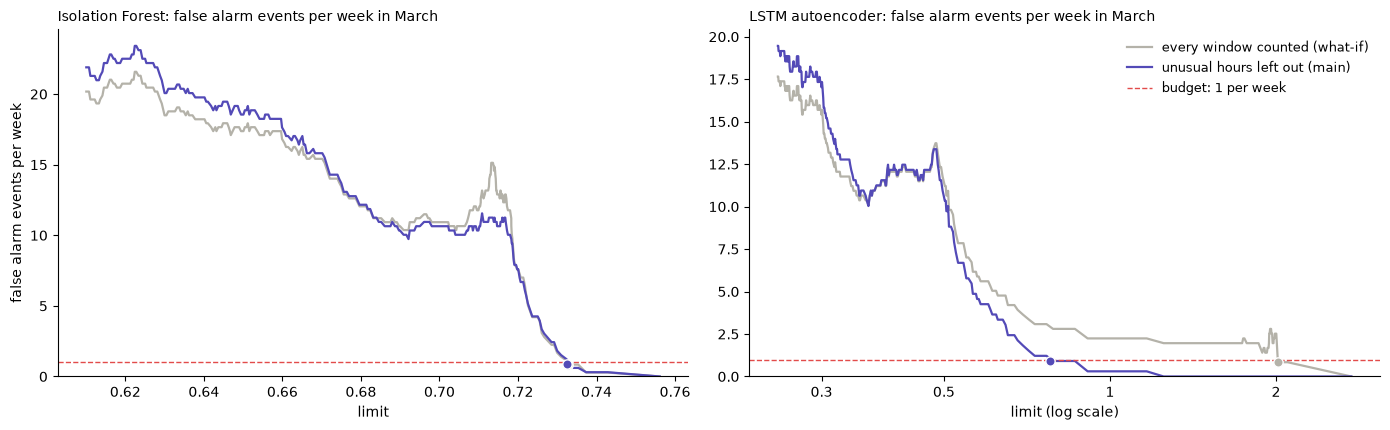

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, model in zip(axes, MODEL_NAMES):
    scores = df_march[model].to_numpy()
    tried = np.unique(np.quantile(scores, np.linspace(0.5, 1, CURVE_POINTS)))
    for version, color in [("all_counted", "#B4B2A9"), ("main", "#534AB7")]:
        per_week = [len(find_events(alarms=alarm_windows(scores=scores, ends=march_ends, limit=limit, in_a_row=IN_A_ROW, step_minutes=WINDOW_STEP_MINUTES),
                                    counted=counted[version], ends=march_ends, merge_gap_minutes=MERGE_GAP_MINUTES)) / weeks[version]
                    for limit in tqdm(tried, desc=f"{MODEL_NAMES[model]}, {VERSION_NAMES[version]}")]
        ax.plot(tried, per_week, color=color, linewidth=1.6, label=VERSION_NAMES[version])
        ax.scatter([limits[model, version]], [len(march_events[model, version]) / weeks[version]], color=color, s=45, zorder=3, edgecolor="white")
    ax.axhline(MAX_FALSE_ALARMS_PER_WEEK, color="#E24B4A", linestyle="--", linewidth=1, label=f"budget: {MAX_FALSE_ALARMS_PER_WEEK} per week")
    if model == "lstm_autoencoder":
        ax.set_xscale("log")
        ax.set_xticks([0.3, 0.5, 1, 2], labels=["0.3", "0.5", "1", "2"])
        ax.minorticks_off()
    ax.set_xlabel("limit (log scale)" if model == "lstm_autoencoder" else "limit")
    ax.set_ylim(bottom=0)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.set_title(f"{MODEL_NAMES[model]}: false alarm events per week in March", fontsize=10, loc="left")
axes[0].set_ylabel("false alarm events per week")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

> **What we see:** going left (a lower limit), the false alarms climb fast. For the forest, the purple and the grey line stay close, and they reach the budget at almost the same limit. For the LSTM, the grey line (every window counted) stays above the budget far to the right, because of the long pump runs; without them, the purple line drops below the budget at a much lower limit. Notebook 5.4 will show the same trade-off on the test months: a lower limit warns earlier, but cries wolf more often.

### The False Alarms That Stay in March

> The false alarm events at the main limits: the moments in March, outside the marked hours, when each model would have called the maintenance team.

In [25]:
event_table = pd.concat([march_events[model, "main"].assign(model=MODEL_NAMES[model]) for model in MODEL_NAMES], ignore_index=True)
event_days = {model: set(march_events[model, "main"]["first_alarm"].dt.day) for model in MODEL_NAMES}
display(event_table[["model", "first_alarm", "last_alarm", "alarms"]].assign(first_alarm=event_table["first_alarm"].dt.strftime("%d %b %H:%M"),
                                                                            last_alarm=event_table["last_alarm"].dt.strftime("%d %b %H:%M")))
print(f"Events in the first half of March: {(event_table['first_alarm'] < pd.Timestamp(HALF_OF_MARCH)).sum()} of {len(event_table)}")
print("Days of March with an event of both models:", sorted(event_days["isolation_forest"] & event_days["lstm_autoencoder"]))

,model,first_alarm,last_alarm,alarms
0,Isolation Forest,02 Mar 10:20,02 Mar 10:25,2
1,Isolation Forest,09 Mar 07:00,09 Mar 07:20,5
2,Isolation Forest,11 Mar 09:30,11 Mar 10:15,7
3,LSTM autoencoder,05 Mar 10:10,05 Mar 10:50,9
4,LSTM autoencoder,09 Mar 07:45,09 Mar 08:45,13
5,LSTM autoencoder,10 Mar 08:15,10 Mar 09:00,10


Events in the first half of March: 6 of 6
Days of March with an event of both models: [9]


> **What we see:** all these events fall in the first half of March (printed above), the time when the compressor pumped more often (notebook 3.2), and the two models share one of the days. These are the false alarms we accept with the budget. In the test months they would be counted like any other false alarm.

### March Day by Day, with the Limits

> Every March window at its end time. The grey bands are the marked windows, which do not count in the main version. The red dashed line is the main limit, the black dotted line the what-if limit, and the red triangles at the top are the false alarm events at the main limit. The LSTM panel has a logarithmic axis, as in notebook 4.2.

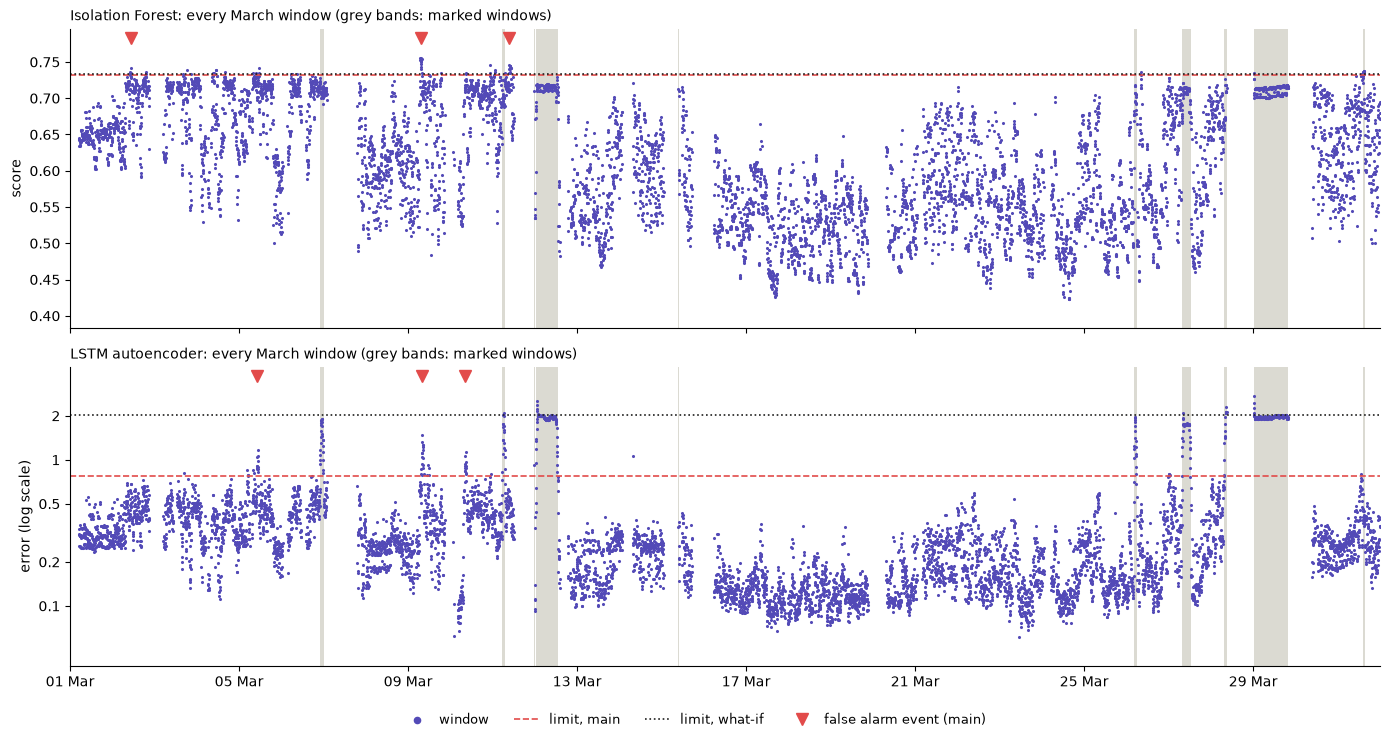

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.4), sharex=True)
for ax, model in zip(axes, MODEL_NAMES):
    for row in stretch_table.itertuples():
        ax.axvspan(row.first_window_end, row.last_window_end + pd.Timedelta(minutes=WINDOW_STEP_MINUTES), color="#D3D1C7", alpha=0.8, linewidth=0)
    ax.scatter(march_ends, df_march[model], s=1.5, color="#534AB7", label="window")
    ax.axhline(limits[model, "main"], color="#E24B4A", linestyle="--", linewidth=1.2, label="limit, main")
    ax.axhline(limits[model, "all_counted"], color="#1F1F1E", linestyle=":", linewidth=1.2, label="limit, what-if")
    ax.plot(march_events[model, "main"]["first_alarm"], np.full(len(march_events[model, "main"]), 0.97), linestyle="none", marker="v",
            markersize=8, color="#E24B4A", transform=ax.get_xaxis_transform(), clip_on=False, label="false alarm event (main)")
    if model == "lstm_autoencoder":
        ax.set_yscale("log")
        ax.set_yticks([0.1, 0.2, 0.5, 1, 2], labels=["0.1", "0.2", "0.5", "1", "2"])
        ax.minorticks_off()
    ax.margins(y=0.12)
    ax.set_ylabel("error (log scale)" if model == "lstm_autoencoder" else "score")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.set_title(f"{MODEL_NAMES[model]}: every March window (grey bands: marked windows)", fontsize=10, loc="left")
march_days = pd.date_range(validation_from, test_from, freq="4D")
axes[-1].set_xticks(march_days, labels=march_days.strftime("%d %b"))
axes[-1].set_xlim(validation_from, test_from)
legend = fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=9)
legend.legend_handles[0].set_sizes([20])
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

> **What we see:** for the forest, the two limits almost overlap, and many March windows sit just below them: its scores are squeezed under the ceiling. For the LSTM, the main limit lies above the normal days of March but far below most errors in the grey bands; the what-if limit lies above almost everything outside the grey bands. In the test months nothing is greyed out: every window counts there.

## How Notebook 5.2 Will Use These Rules

> These rules are fixed now, before any test window gets a score:
>
> - Notebook 5.2 scores the test windows with the same two model files. A check compares their fingerprints with the ones saved here, so a retrained model cannot use these limits by accident.
> - Each model uses its **main** limit, 3 windows in a row and the 60-minute merge. The alarm rule runs over the test windows from 1 April on, the same way as over March here.
> - Every alarm gets the zone of its time (the end of its window), with the zones of notebook 1.2: healthy, warning, leak or ignored. Nothing is left out in the test months.
> - A leak is **caught** when an alarm comes in its warning zone or during the leak. The **lead time** is the leak start minus the first such alarm.
> - **False alarms** are the events formed by the alarms in healthy time, merged with the same 60-minute rule, per week of monitored healthy time (healthy windows times 5 minutes).
> - Alarms in the ignored zone are counted and reported, but not as right or wrong.
> - The what-if limits (every March window counted) are used only in notebook 5.4.

## Save

### What Will Be Written

> A preview of the rules file: the alarm rule, the rule for unusual March hours, the limits of both models in both versions, what they gave in March, the fingerprints of the two model files, and the fingerprint of all of this.

In [27]:
rules = {
    "alarm_rule": {"in_a_row": IN_A_ROW, "window_step_minutes": WINDOW_STEP_MINUTES, "merge_gap_minutes": MERGE_GAP_MINUTES,
                   "max_false_alarms_per_week": MAX_FALSE_ALARMS_PER_WEEK},
    "unusual_march_hours": {"pump_signal": PUMP_COLUMN, "long_pump_minutes": LONG_PUMP_MINUTES, "low_pressure_signal": LOW_PRESSURE_COLUMN,
                            "marked_march_windows": int(marked_in_march.sum()), "march_windows": int(is_march.sum())},
    "limits": {model: {version: float(limits[model, version]) for version in VERSION_NAMES} for model in MODEL_NAMES},
    "march": {model: {version: {"false_alarm_events": len(march_events[model, version]), "monitored_weeks": float(weeks[version])}
                      for version in VERSION_NAMES} for model in MODEL_NAMES},
    "model_files": {os.path.basename(path): file_fingerprint(path=path) for path in [FOREST_FILE, LSTM_FILE]},
}
rules["fingerprint"] = rules_fingerprint(rules=rules)

print(json.dumps(rules, indent=2))
print(f"\n{os.path.relpath(RULES_FILE, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(RULES_FILE) else 'new file'}")

{
  "alarm_rule": {
    "in_a_row": 3,
    "window_step_minutes": 5,
    "merge_gap_minutes": 60,
    "max_false_alarms_per_week": 1
  },
  "unusual_march_hours": {
    "pump_signal": "DV_eletric",
    "long_pump_minutes": 30,
    "low_pressure_signal": "LPS",
    "marked_march_windows": 564,
    "march_windows": 7194
  },
  "limits": {
    "isolation_forest": {
      "main": 0.7325970047906787,
      "all_counted": 0.7327661460419287
    },
    "lstm_autoencoder": {
      "main": 0.7800137996673584,
      "all_counted": 2.0189945697784424
    }
  },
  "march": {
    "isolation_forest": {
      "main": {
        "false_alarm_events": 3,
        "monitored_weeks": 3.2886904761904763
      },
      "all_counted": {
        "false_alarm_events": 3,
        "monitored_weeks": 3.568452380952381
      }
    },
    "lstm_autoencoder": {
      "main": {
        "false_alarm_events": 3,
        "monitored_weeks": 3.2886904761904763
      },
      "all_counted": {
        "false_alarm_events": 3

### Save the Alarm Rules

In [28]:
os.makedirs(RESULTS_DIR, exist_ok=True)
with open(RULES_FILE, "w", encoding="utf-8") as f:
    json.dump(rules, f, indent=2)
print(f"Saved {os.path.relpath(RULES_FILE, ROOT_DIR)} ({os.path.getsize(RULES_FILE) / 1024:,.1f} KB)")

Saved results\alarm_rules.json (1.4 KB)


### Read the File Back

> We read the file again, as notebook 5.2 will: its fingerprint must match its content, and its limits must give the same false alarm events in March.

In [29]:
with open(RULES_FILE, encoding="utf-8") as f:
    saved_rules = json.load(f)
again = {}
for model in MODEL_NAMES:
    for version in VERSION_NAMES:
        alarms = alarm_windows(scores=df_march[model].to_numpy(), ends=march_ends, limit=saved_rules["limits"][model][version],
                               in_a_row=IN_A_ROW, step_minutes=WINDOW_STEP_MINUTES)
        again[model, version] = len(find_events(alarms=alarms, counted=counted[version], ends=march_ends, merge_gap_minutes=MERGE_GAP_MINUTES))

print("Fingerprint of the rules:", saved_rules["fingerprint"])
check("the fingerprint matches the saved rules", rules_fingerprint(rules=saved_rules) == saved_rules["fingerprint"])
check("the saved limits give the same false alarm events in March",
      all(again[model, version] == saved_rules["march"][model][version]["false_alarm_events"] for model, version in again))

Fingerprint of the rules: 588120871ddc1d4b931906a50e38a7486bf7daf92e8d633bf966260d015a5784
PASS  the fingerprint matches the saved rules
PASS  the saved limits give the same false alarm events in March


## Result

### Final Result

> If every check passed, the alarm rule and the limits of both models are set on March only, and locked. If a check failed, its name is printed.

In [30]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (10 checks)


## Summary

> - An alarm needs 3 windows in a row above the limit, and alarms at most 60 minutes apart are one event. False alarms are counted as events per week of monitored time.
> - Unusual March hours (the pump running without a break for 30 minutes or more, or `LPS` on) are left out when the limits are set. The rule marks nothing in February. A clue about the cause: after a stop of the train, the tanks kept their air in February but often lost it in March, which looks like escaping air. No failure is reported in March, so the cause stays unknown.
> - The limit of each model is the lowest one that keeps March at 1 false alarm event per week or less. For the forest it sits in the bunch of high scores under its ceiling, just below the highest February score; for the LSTM it sits well above every February window.
> - Leaving the unusual hours out changes the limit of the LSTM a lot, and the limit of the forest hardly at all. The limits with every window counted are kept as a what-if for notebook 5.4.
> - The rules, the limits and the fingerprints of the two model files are locked in `results/alarm_rules.json`. Notebook 5.2 applies them to the test months, where every window counts.
>
> **Next:** `notebooks/5_evaluation/5.2_test_results.ipynb`